<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" width="150" alt="VGI"></a>

# Which older files are absent from the tracking sheet?

Joining a Drive listing to a Sheet can look straightforward until duplicated IDs amplify rows, dates are missing and file sizes are unknown. We will use the real Google worker to fetch a **synthetic paginated PDF listing** and a **synthetic tracking range**, then reconcile them in visible SQL.

No Google account or credentials are involved. An explicit local transport hook supplies authored response bodies to Google’s real discovery client and the unchanged worker adapters. [Fixture notes](fixtures/README.md) describe the construction; [running instructions](README.md) pin the runtime. These are fictional files, not evidence about an account or instructions to change files.

## Choose the elapsed-age threshold

`MIN_AGE_DAYS` accepts integers 0–365. An unlogged file qualifies when its known modification age is **at least** this many elapsed 24-hour days as of **2026-04-01 00:00 UTC**. Future and missing timestamps are separate outcomes. The clock is a fixed synthetic reference, not execution time. Edit the value, restart the kernel and run all; listing scope and page coverage stay fixed.

In [1]:
MIN_AGE_DAYS = 30  # Inclusive elapsed days since modification; experiment: 90

In [2]:
import haybarn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import MaxNLocator

from notebook_support import chart, cleanup, configure, prose, theme, verify_audit

previous, audit_path = configure(MIN_AGE_DAYS)
theme()
connection = haybarn.connect()
connection.execute("SET TimeZone='UTC'")
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaylimit = 20
%sql connection

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-google/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-google/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-google/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-google/notebooks/pyproject.toml.

## Materialize the real worker’s paginated reads

The literal launcher imports the published Git-tag worker and installs only the existing transport test hook. The transport allows two explicit **GET** shapes and has no network fallback. Drive’s continuation state, field mapping and Arrow output remain in the worker; Sheets still consumes its header and builds JSON records.

The row cap is above the complete fixture size. We materialize each adapter call once, then capture only local tables, so display cannot repeat API-style reads.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
LOAD json;
ATTACH 'google' (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with pyarrow==26.0.1 --with google-api-python-client==2.201.0 --with google-auth==2.62.1 --with httplib2==0.32.1 --with google-auth-httplib2==0.4.4 --from git+https://github.com/Query-farm/vgi-google@v0.4.0 python fixture_worker.py');
CREATE TABLE settings AS SELECT {{ MIN_AGE_DAYS }}::INTEGER AS min_age_days,
    TIMESTAMPTZ '2026-04-01 00:00:00+00' AS as_of_utc;
CREATE TABLE drive_files AS
SELECT * FROM google.google_drive(
    query := 'mimeType=''application/pdf'' and trashed=false', count := 100, page_size := 3);
CREATE TABLE sheet_rows AS
SELECT * FROM google.google_sheet('tracking-demo','Log!A1:B50',header := true,count := 100);


Running query in 'DuckDBPyConnection'

1 rows affected.

9 rows affected.

6 rows affected.

,Count


## Normalize the ledger key before joining

Drive IDs are opaque and case-sensitive. We trim accidental surrounding whitespace in the Sheet but preserve case. Blank or absent IDs are excluded from the key set. A distinct key table makes membership a yes/no question without multiplying Drive rows when the ledger contains duplicates.

An ID that is not in this PDF listing is reported as **absent from this scope**, not as a deleted file.

In [4]:
%%sql
CREATE TABLE ledger_rows AS
SELECT row_number, nullif(trim(record ->> '$.file_id'),'') AS file_id
FROM sheet_rows;
CREATE TABLE ledger_keys AS SELECT DISTINCT file_id FROM ledger_rows WHERE file_id IS NOT NULL;
CREATE TABLE ledger_outside_scope AS
SELECT file_id FROM ledger_keys ANTI JOIN drive_files ON file_id=id;
CREATE TABLE diagnostics AS
SELECT (SELECT count(*) FROM drive_files) AS drive_rows,
       (SELECT count(*) FROM ledger_rows) AS ledger_rows,
       (SELECT count(*) FROM ledger_rows WHERE file_id IS NULL) AS blank_or_missing_ids,
       (SELECT count(file_id)-count(DISTINCT file_id) FROM ledger_rows) AS duplicate_key_rows,
       (SELECT count(*) FROM ledger_keys) AS distinct_ledger_keys,
       (SELECT count(*) FROM ledger_outside_scope) AS keys_absent_from_listing,
       (SELECT count(*) FROM drive_files WHERE modified_time IS NULL) AS unknown_modified_times,
       (SELECT count(*) FROM drive_files WHERE size IS NULL) AS unknown_sizes,
       (SELECT count(*) FROM drive_files WHERE size=0) AS observed_zero_sizes;

Running query in 'DuckDBPyConnection'

6 rows affected.

3 rows affected.

1 rows affected.

1 rows affected.

,Count


In [5]:
%%sql diagnostics_frame <<
SELECT * FROM diagnostics;

Running query in 'DuckDBPyConnection'

In [6]:
%%sql outside_scope <<
SELECT * FROM ledger_outside_scope ORDER BY file_id;

Running query in 'DuckDBPyConnection'

In [7]:
display(diagnostics_frame)
display(outside_scope)
d = diagnostics_frame.iloc[0]
prose(
    f"The ledger has **{int(d.duplicate_key_rows)} duplicate key row(s)** after trimming and "
    f"**{int(d.blank_or_missing_ids)} blank/missing IDs**. Its **{int(d.keys_absent_from_listing)}** "
    "out-of-scope key is not evidence of deletion. "
    f"The listing contains **{int(d.unknown_sizes)} unknown size(s)** and "
    f"**{int(d.observed_zero_sizes)} observed zero size(s)**; those meanings stay separate."
)

,drive_rows,ledger_rows,blank_or_missing_ids,duplicate_key_rows,distinct_ledger_keys,keys_absent_from_listing,unknown_modified_times,unknown_sizes,observed_zero_sizes
0,9,6,2,1,3,1,1,1,1


,file_id
0,DOC-OLD


The ledger has **1 duplicate key row(s)** after trimming and **2 blank/missing IDs**. Its **1** out-of-scope key is not evidence of deletion. The listing contains **1 unknown size(s)** and **1 observed zero size(s)**; those meanings stay separate.

## Build a disjoint reconciliation

Membership in the ledger takes precedence. Among unlogged files, unknown modification time, future timestamp, old-enough and more-recent files are separate categories. Age is elapsed seconds divided by 86,400, avoiding calendar-boundary or local-time ambiguity. This classifies the current filtered listing; it does not scan the whole Drive account.

In [8]:
%%sql
CREATE TABLE aged AS
SELECT d.*, k.file_id IS NOT NULL AS in_ledger,
       date_diff('second',d.modified_time,s.as_of_utc)/86400.0 AS age_days
FROM drive_files d LEFT JOIN ledger_keys k ON d.id=k.file_id CROSS JOIN settings s;
CREATE TABLE reconciled AS
SELECT a.*, CASE WHEN in_ledger THEN 'Listed in ledger'
    WHEN modified_time IS NULL THEN 'Unknown modification time'
    WHEN age_days<0 THEN 'Future timestamp'
    WHEN age_days>=s.min_age_days THEN 'Unlogged, old enough'
    ELSE 'Unlogged, recent' END AS bucket
FROM aged a CROSS JOIN settings s;
CREATE TABLE shortlist AS SELECT id,name,modified_time,age_days,size
FROM reconciled WHERE bucket='Unlogged, old enough';
CREATE TABLE bucket_summary AS
WITH labels AS (SELECT * FROM (VALUES
    (1,'Listed in ledger'),(2,'Unlogged, old enough'),(3,'Unlogged, recent'),
    (4,'Future timestamp'),(5,'Unknown modification time')) t(sort_order,bucket))
SELECT l.sort_order,l.bucket,count(r.id) AS files,count(r.size) AS known_sizes,
       count(r.id)-count(r.size) AS unknown_sizes,sum(r.size)/1048576.0 AS known_mib
FROM labels l LEFT JOIN reconciled r USING(bucket)
GROUP BY l.sort_order,l.bucket;

Running query in 'DuckDBPyConnection'

9 rows affected.

9 rows affected.

3 rows affected.

5 rows affected.

,Count


In [9]:
%%sql shortlist_frame <<
SELECT id,name,modified_time AT TIME ZONE 'UTC' AS modified_time_utc,age_days,
       size/1048576.0 AS size_mib FROM shortlist ORDER BY age_days DESC,id;

Running query in 'DuckDBPyConnection'

In [10]:
%%sql age_frame <<
SELECT id,name,age_days,bucket FROM reconciled
WHERE NOT in_ledger AND modified_time IS NOT NULL ORDER BY age_days DESC,id;

Running query in 'DuckDBPyConnection'

In [11]:
%%sql buckets <<
SELECT * FROM bucket_summary ORDER BY sort_order;

Running query in 'DuckDBPyConnection'

In [12]:
display(shortlist_frame)
selected = buckets.loc[buckets.bucket.eq("Unlogged, old enough")].iloc[0]
prose(
    f"At **{MIN_AGE_DAYS} elapsed days**, **{int(selected.files)} unlogged file(s)** qualify. "
    f"Their observed sizes cover **{int(selected.known_sizes)} file(s)**, while "
    f"**{int(selected.unknown_sizes)} size(s)** remain unknown. "
    "The next plots compare the age cutoff with the listing-wide reconciliation; "
    "a sum of known sizes is not a complete byte total when any size is absent."
)

,id,name,modified_time_utc,age_days,size_mib
0,DOC-C,Legacy migration guide,2025-12-02,120.0,8.0
1,DOC-D,Capacity planning notes,2026-01-16,75.0,3.0
2,DOC-E,Schema compatibility report,2026-02-20,40.0,NaN


At **30 elapsed days**, **3 unlogged file(s)** qualify. Their observed sizes cover **2 file(s)**, while **1 size(s)** remain unknown. The next plots compare the age cutoff with the listing-wide reconciliation; a sum of known sizes is not a complete byte total when any size is absent.

findfont: Failed to find font weight semibold for Arial, now using 700.


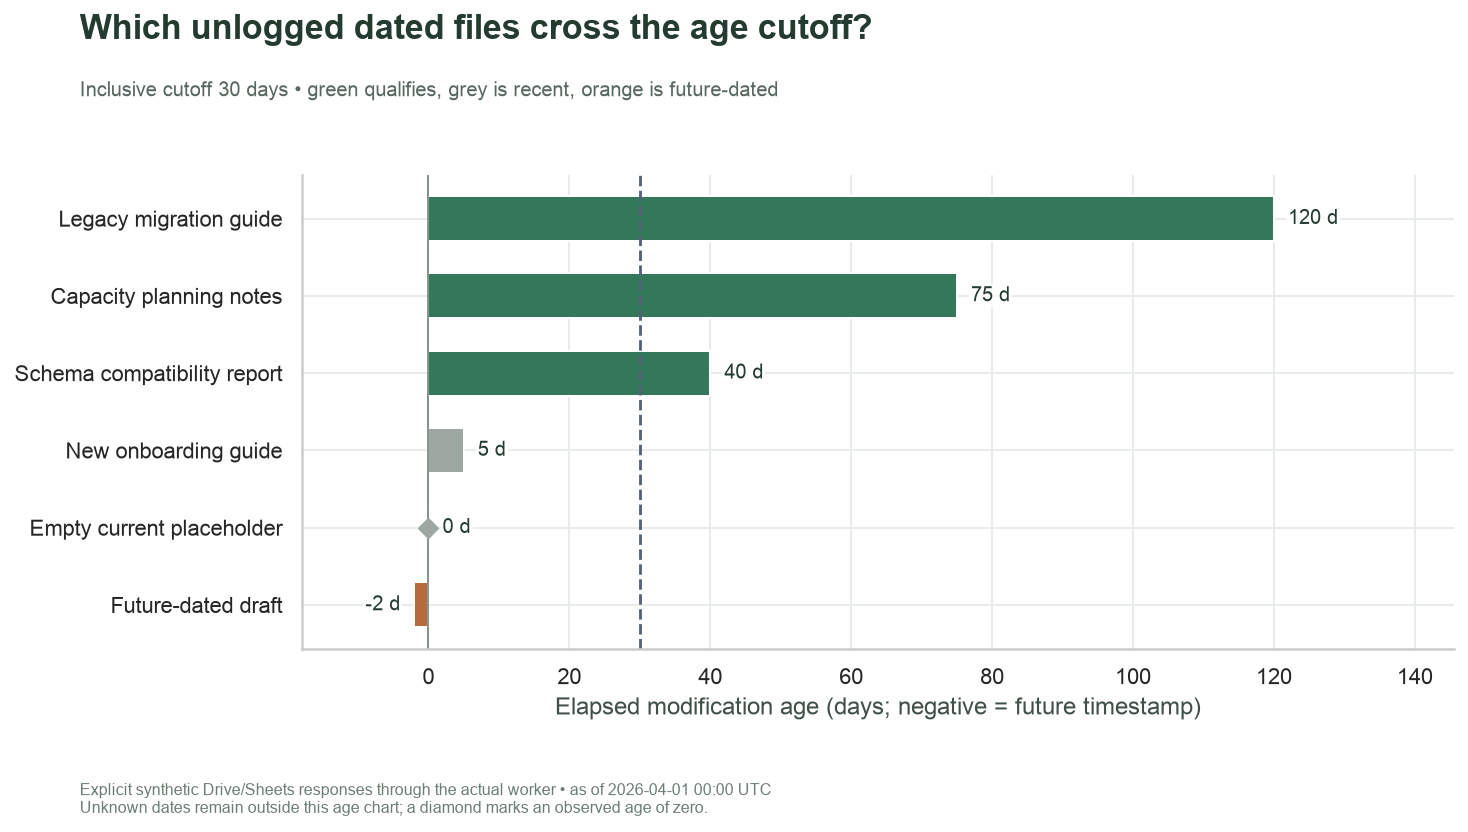

In [13]:
colors = {
    "Listed in ledger": "#536C91",
    "Unlogged, old enough": "#34785B",
    "Unlogged, recent": "#9CA8A1",
    "Future timestamp": "#B66B3D",
    "Unknown modification time": "#8C789F",
}
fig, ax = plt.subplots(figsize=(10.5, 5.8))
y = np.arange(len(age_frame))
ax.barh(y, age_frame.age_days, color=[colors[s] for s in age_frame.bucket], height=0.58)
for i, row in enumerate(age_frame.itertuples()):
    if row.age_days == 0:
        ax.scatter([0], [i], marker="D", color=colors[row.bucket], s=45, zorder=4)
    ax.text(
        row.age_days + (2 if row.age_days >= 0 else -2),
        i,
        f"{row.age_days:g} d",
        ha="left" if row.age_days >= 0 else "right",
        va="center",
        fontsize=10,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9, "pad": 1},
    )
ax.axvline(MIN_AGE_DAYS, color="#536077", linestyle="--", linewidth=1.4)
ax.axvline(0, color="#6C7D73", linewidth=0.8)
ax.set_yticks(y, age_frame.name)
ax.invert_yaxis()
ax.set_xlim(min(-18, age_frame.age_days.min() - 12), max(MIN_AGE_DAYS, age_frame.age_days.max()) * 1.18 + 4)
ax.set_xlabel("Elapsed modification age (days; negative = future timestamp)")
chart(
    fig,
    "Which unlogged dated files cross the age cutoff?",
    f"Inclusive cutoff {MIN_AGE_DAYS} days • green qualifies, grey is recent, orange is future-dated",
    "Explicit synthetic Drive/Sheets responses through the actual worker • as of 2026-04-01 00:00 UTC\n"
    "Unknown dates remain outside this age chart; a diamond marks an observed age of zero.",
)

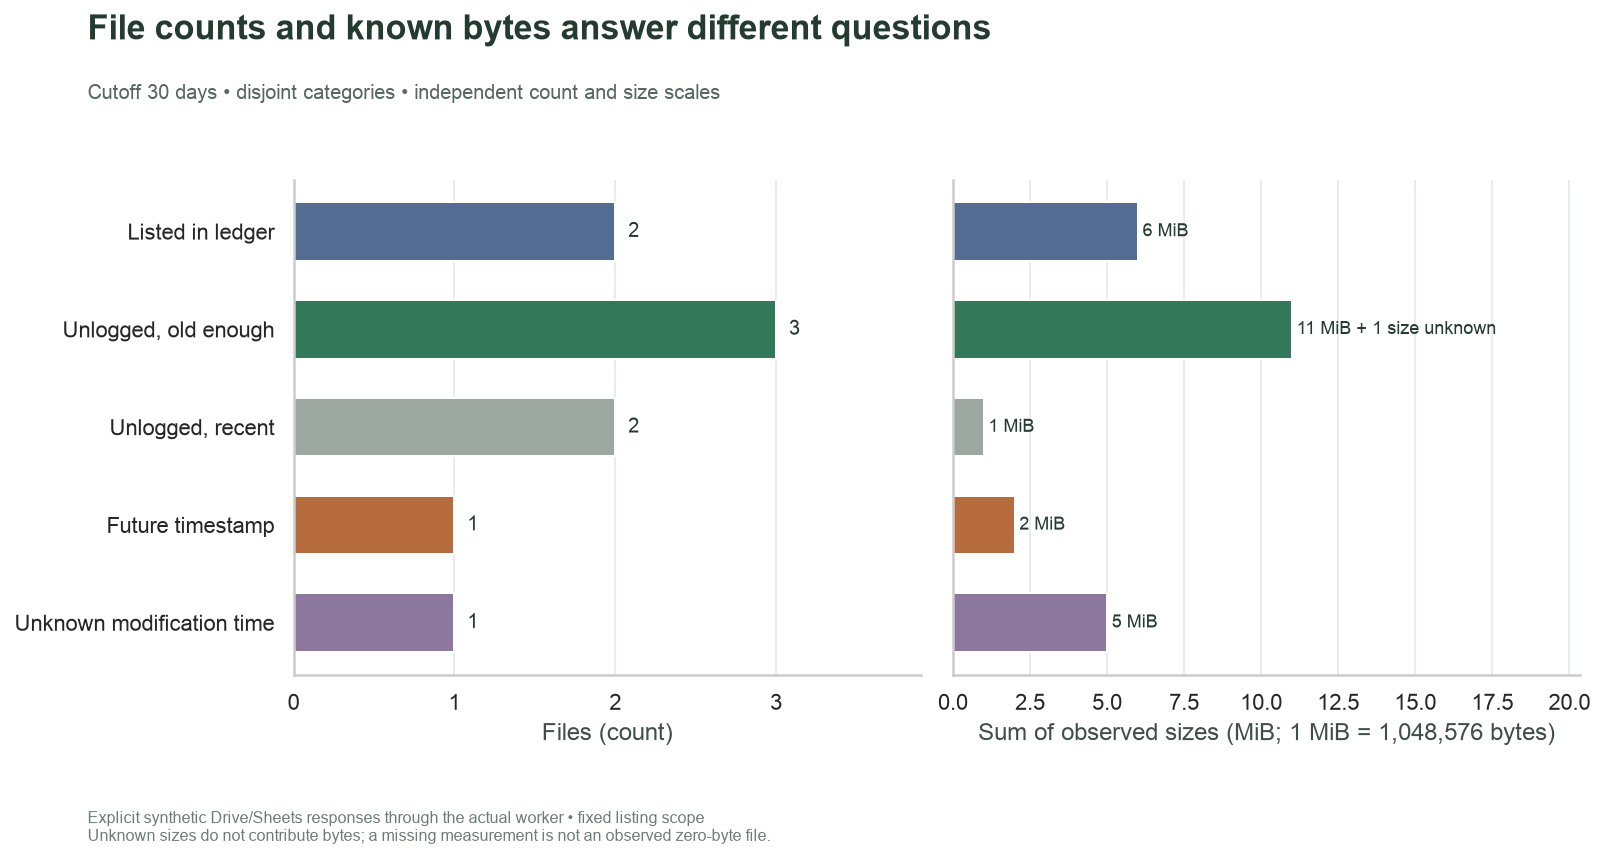

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11.4, 6))
y = np.arange(len(buckets))
axes[0].barh(y, buckets.files, color=[colors[s] for s in buckets.bucket], height=0.6)
for i, row in enumerate(buckets.itertuples()):
    axes[0].text(row.files + 0.08, i, str(row.files), va="center", fontsize=10)
    if row.files == 0:
        axes[1].text(0.1, i, "No files", va="center", color="#6C7D73")
    elif pd.isna(row.known_mib):
        axes[1].text(0.1, i, "No known sizes", va="center", color="#A85637")
    else:
        axes[1].barh(i, row.known_mib, color=colors[row.bucket], height=0.6)
        suffix = f" + {row.unknown_sizes} size unknown" if row.unknown_sizes else ""
        axes[1].text(row.known_mib + 0.15, i, f"{row.known_mib:g} MiB{suffix}", va="center", fontsize=9)
for ax in axes:
    ax.set_yticks(y, buckets.bucket if ax is axes[0] else [])
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
axes[0].set_xlim(0, max(1, buckets.files.max()) * 1.3)
axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].set_xlabel("Files (count)")
axes[1].set_xlim(0, max(1, buckets.known_mib.max()) * 1.85)
axes[1].set_xlabel("Sum of observed sizes (MiB; 1 MiB = 1,048,576 bytes)")
chart(
    fig,
    "File counts and known bytes answer different questions",
    f"Cutoff {MIN_AGE_DAYS} days • disjoint categories • independent count and size scales",
    "Explicit synthetic Drive/Sheets responses through the actual worker • fixed listing scope\n"
    "Unknown sizes do not contribute bytes; a missing measurement is not an observed zero-byte file.",
)

The categories partition the listing, so their file counts reconcile exactly. The size panel sums only observed byte values and annotates absent measurements. Tightening the age cutoff changes the shortlist, but the input listing, ledger keys and total number of files remain fixed.

## Verify pagination and reconciliation

The SQL checks compare the distinct-key left join with an independent anti join and compare the elapsed-age formula with a direct UTC cutoff. They also verify key uniqueness, scope, count partitions and size semantics. A separate transport audit confirms complete, non-repeated page retrieval. These are data and transport checks, not proof that a real tracking process is current.

In [15]:
%%sql checks <<
WITH independent_shortlist AS (
    SELECT d.id FROM drive_files d ANTI JOIN ledger_keys k ON d.id=k.file_id
    CROSS JOIN settings s WHERE d.modified_time IS NOT NULL
      AND d.modified_time<=s.as_of_utc-s.min_age_days*INTERVAL '1 day'
), difference AS (
    (SELECT id FROM shortlist EXCEPT SELECT id FROM independent_shortlist)
    UNION ALL (SELECT id FROM independent_shortlist EXCEPT SELECT id FROM shortlist)
)
SELECT 'Drive identifiers are present and unique' AS check_name,
       NOT EXISTS(SELECT id FROM drive_files GROUP BY id HAVING id IS NULL OR id='' OR count(*)<>1) AS passed
UNION ALL SELECT 'Distinct ledger keys are nonblank and trimmed',
       NOT EXISTS(SELECT file_id FROM ledger_keys GROUP BY file_id
                  HAVING file_id IS NULL OR file_id='' OR file_id<>trim(file_id) OR count(*)<>1)
UNION ALL SELECT 'Ledger join preserves listing cardinality',
       (SELECT count(*) FROM reconciled)=(SELECT count(*) FROM drive_files)
UNION ALL SELECT 'Returned files match the requested PDF scope',
       NOT EXISTS(SELECT 1 FROM drive_files WHERE mime_type IS DISTINCT FROM 'application/pdf'
                  OR trashed IS DISTINCT FROM FALSE)
UNION ALL SELECT 'Stored sizes are unknown or nonnegative',
       NOT EXISTS(SELECT 1 FROM drive_files WHERE size<0)
UNION ALL SELECT 'Disjoint bucket counts reconcile to listing',
       (SELECT sum(files) FROM bucket_summary)=(SELECT count(*) FROM drive_files)
UNION ALL SELECT 'Known and unknown size counts partition each bucket',
       NOT EXISTS(SELECT 1 FROM bucket_summary WHERE files<>known_sizes+unknown_sizes)
UNION ALL SELECT 'Known byte sums reconcile across buckets',
       (SELECT sum(known_mib) FROM bucket_summary)=(SELECT sum(size)/1048576.0 FROM drive_files)
UNION ALL SELECT 'Anti join and direct UTC cutoff agree with shortlist', NOT EXISTS(SELECT 1 FROM difference)
UNION ALL SELECT 'Ledger keys partition into in-scope and absent',
       (SELECT count(*) FROM ledger_keys)=
       (SELECT count(*) FROM ledger_keys JOIN drive_files ON file_id=id)
       +(SELECT count(*) FROM ledger_outside_scope);

Running query in 'DuckDBPyConnection'

In [16]:
display(checks)
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
prose(verify_audit(audit_path))

,check_name,passed
0,Drive identifiers are present and unique,True
1,Distinct ledger keys are nonblank and trimmed,True
2,Ledger join preserves listing cardinality,True
3,Returned files match the requested PDF scope,True
4,Stored sizes are unknown or nonnegative,True
5,Disjoint bucket counts reconcile to listing,True
6,Known and unknown size counts partition each b...,True
7,Known byte sums reconcile across buckets,True
8,Anti join and direct UTC cutoff agree with sho...,True
9,Ledger keys partition into in-scope and absent,True


Transport audit passed: three successive Drive page tokens and one Sheets fetch, with no repeated calls.

## Experiment: tighten only the age cutoff

Change **`MIN_AGE_DAYS = 30` to `90`**, restart and run all, or use the README’s separate-output command. Predict which unlogged files leave the shortlist. Compare its file count, known MiB, unknown-size count and category bars.

The reference time, PDF query, complete three-page listing and deduplicated ledger remain fixed. A shrinking shortlist is a stricter analytical rule, not a change in account contents or evidence that work was completed. An unknown size becoming excluded also does not imply a zero-byte file. Reset **`MIN_AGE_DAYS = 30`** for defaults. This walkthrough reads only; it never writes to a Sheet or modifies a Drive file.

In [17]:
connection.close()
cleanup(previous)

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>